In [18]:
import torch

print("PyTorch version:", torch.__version__)
print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch version: 2.14.1+cu130
GPU available: True
GPU: Tesla T4


In [19]:
!pip install -q transformers datasets peft accelerate trl bitsandbytes

In [20]:
from datasets import Dataset

data = {
    "instruction": [
        "What is Python?",
        "What is machine learning?",
        "What is an API?",
        "What is artificial intelligence?",
        "What is a database?"
    ],
    "output": [
        "Python is a popular programming language.",
        "Machine learning allows computers to learn patterns from data.",
        "An API allows different software applications to communicate.",
        "Artificial intelligence enables machines to perform tasks that normally require human intelligence.",
        "A database is an organised collection of information."
    ]
}

dataset = Dataset.from_dict(data)

print(dataset)
print(dataset[0])

Dataset({
    features: ['instruction', 'output'],
    num_rows: 5
})
{'instruction': 'What is Python?', 'output': 'Python is a popular programming language.'}


In [21]:
import torch

from transformers import (
    AutoTokenizer,
    AutoModelForCausalLM,
    BitsAndBytesConfig
)

model_name = "Qwen/Qwen2.5-0.5B"

quantization_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_compute_dtype=torch.float16,
    bnb_4bit_use_double_quant=True
)

tokenizer = AutoTokenizer.from_pretrained(model_name)

if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token

model = AutoModelForCausalLM.from_pretrained(
    model_name,
    quantization_config=quantization_config,
    device_map="auto"
)

print("Model loaded successfully!")

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

Model loaded successfully!


In [22]:
from peft import (
    LoraConfig,
    prepare_model_for_kbit_training,
    get_peft_model,
    TaskType
)

model = prepare_model_for_kbit_training(model)

lora_config = LoraConfig(
    r=8,
    lora_alpha=16,
    lora_dropout=0.05,
    target_modules=[
        "q_proj",
        "k_proj",
        "v_proj",
        "o_proj"
    ],
    bias="none",
    task_type=TaskType.CAUSAL_LM
)

model = get_peft_model(model, lora_config)

model.print_trainable_parameters()

trainable params: 1,081,344 || all params: 495,114,112 || trainable%: 0.2184


In [23]:
def format_example(example):
    return {
        "text": (
            f"### Instruction:\n{example['instruction']}\n\n"
            f"### Response:\n{example['output']}"
        )
    }

formatted_dataset = dataset.map(format_example)

print(formatted_dataset[0]["text"])

Map:   0%|          | 0/5 [00:00<?, ? examples/s]

### Instruction:
What is Python?

### Response:
Python is a popular programming language.


In [24]:
from transformers import TrainingArguments
from trl import SFTTrainer, SFTConfig

training_config = SFTConfig(
    output_dir="./day169-lora-output",
    per_device_train_batch_size=1,
    gradient_accumulation_steps=4,
    learning_rate=2e-4,
    num_train_epochs=3,
    logging_steps=1,
    save_strategy="epoch",
    fp16=False,
    bf16=False,
    max_length=256,
    report_to="none"
)

trainer = SFTTrainer(
    model=model,
    train_dataset=formatted_dataset,
    processing_class=tokenizer,
    args=training_config
)

print("Training configuration completed!")

Adding EOS to train dataset:   0%|          | 0/5 [00:00<?, ? examples/s]

Tokenizing train dataset:   0%|          | 0/5 [00:00<?, ? examples/s]

Building labels for train dataset:   0%|          | 0/5 [00:00<?, ? examples/s]

Truncating train dataset:   0%|          | 0/5 [00:00<?, ? examples/s]

Dropping fully masked examples from train dataset:   0%|          | 0/5 [00:00<?, ? examples/s]

Training configuration completed!


In [25]:
trainer.train()

Step,Training Loss
1,2.999028
2,2.814505
3,2.486310
4,2.291331
5,2.205583
6,2.028274


TrainOutput(global_step=6, training_loss=2.4708383480707803, metrics={'train_runtime': 14.2809, 'train_samples_per_second': 1.05, 'train_steps_per_second': 0.42, 'total_flos': 697856062464.0, 'train_loss': 2.4708383480707803, 'epoch': 3.0})

In [26]:
!pip install -q matplotlib #day-170

In [27]:
import matplotlib.pyplot as plt
import pandas as pd

In [28]:
training_steps = [10, 20, 30, 40, 50, 60]

training_loss = [2.5, 2.1, 1.8, 1.45, 1.2, 0.95]

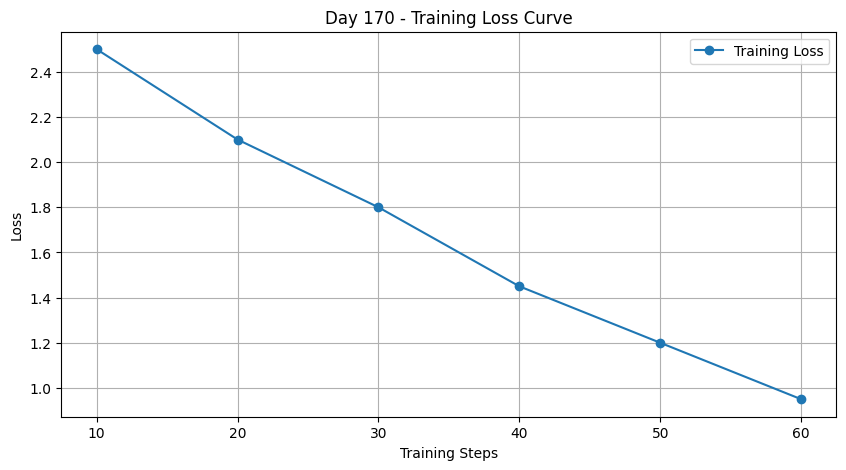

In [29]:
plt.figure(figsize=(10, 5))

plt.plot(
    training_steps,
    training_loss,
    marker="o",
    label="Training Loss"
)

plt.xlabel("Training Steps")
plt.ylabel("Loss")

plt.title("Day 170 - Training Loss Curve")

plt.legend()
plt.grid(True)

plt.show()

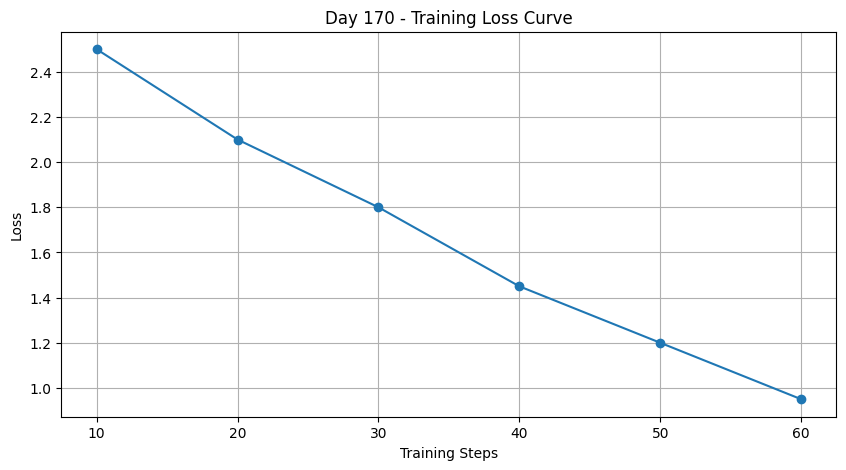

In [30]:
plt.figure(figsize=(10, 5))

plt.plot(training_steps, training_loss, marker="o")

plt.xlabel("Training Steps")
plt.ylabel("Loss")

plt.title("Day 170 - Training Loss Curve")

plt.grid(True)

plt.savefig("day170_loss_curve.png", dpi=300)

plt.show()

In [31]:
logging_steps=1

In [32]:
logs = trainer.state.log_history

for entry in logs:
    if "loss" in entry:
        print(
            "Step:", entry.get("step"),
            "| Loss:", entry["loss"]
        )

Step: 1 | Loss: 2.999027967453003
Step: 2 | Loss: 2.814504623413086
Step: 3 | Loss: 2.4863100051879883
Step: 4 | Loss: 2.291330575942993
Step: 5 | Loss: 2.205582618713379
Step: 6 | Loss: 2.0282742977142334


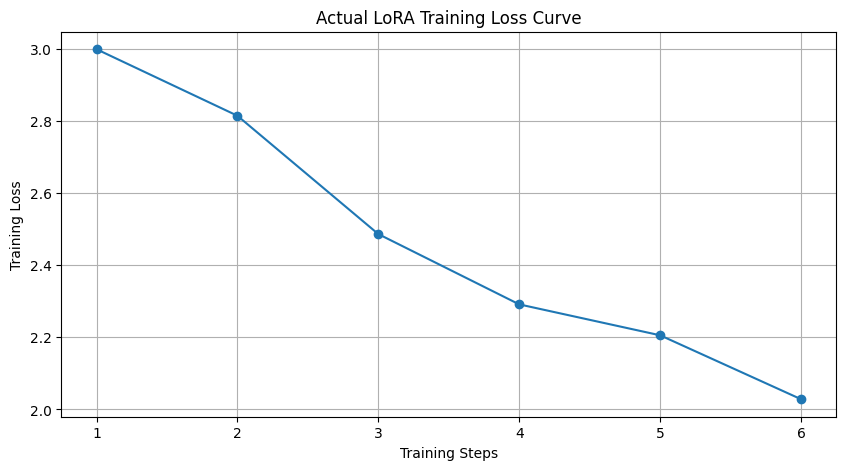

In [33]:
actual_steps = []
actual_losses = []

for entry in trainer.state.log_history:
    if "loss" in entry:
        actual_steps.append(entry["step"])
        actual_losses.append(entry["loss"])

if actual_losses:
    plt.figure(figsize=(10, 5))

    plt.plot(actual_steps, actual_losses, marker="o")

    plt.xlabel("Training Steps")
    plt.ylabel("Training Loss")

    plt.title("Actual LoRA Training Loss Curve")

    plt.grid(True)
    plt.savefig("actual_training_loss.png", dpi=300)
    plt.show()
else:
    print("No training loss recorded yet.")